In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error

In [2]:
df = pd.read_csv("Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [3]:
df.shape

(10000, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [5]:
# check null values
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

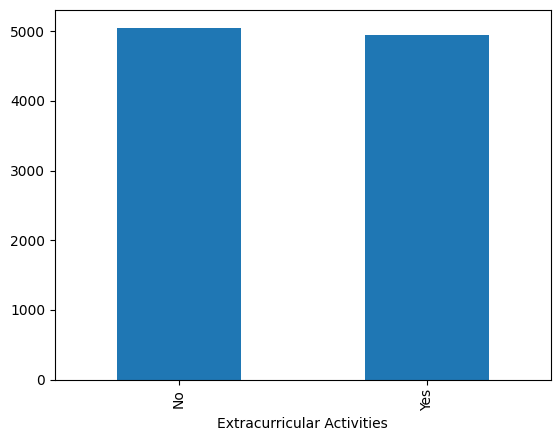

In [6]:
df["Extracurricular Activities"].value_counts().plot(kind="bar")
plt.show()

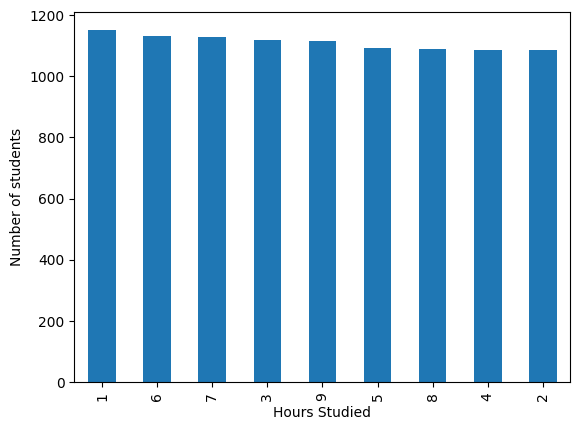

In [7]:
df["Hours Studied"].value_counts().plot(kind="bar")
plt.ylabel("Number of students")
plt.show()

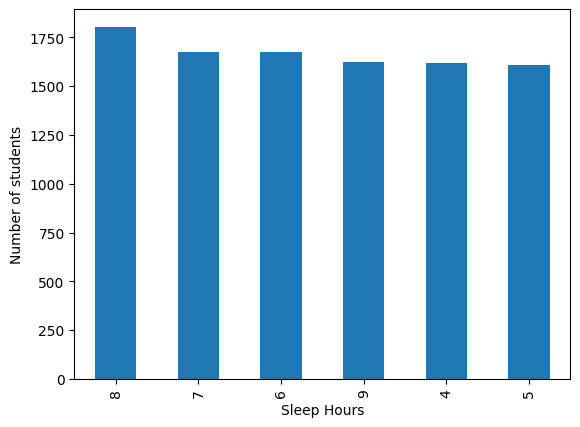

In [8]:
df["Sleep Hours"].value_counts().plot(kind="bar")
plt.ylabel("Number of students")
plt.show()

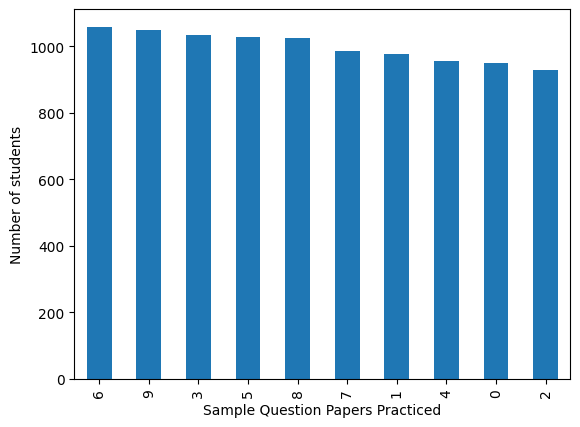

In [9]:
df["Sample Question Papers Practiced"].value_counts().plot(kind="bar")
plt.ylabel("Number of students")
plt.show()

In [10]:
# convert categorical column into numerical
oe = OneHotEncoder(sparse_output=False,drop = "first", dtype=np.int8)
df["Extracurricular Activities"] = oe.fit_transform(df[["Extracurricular Activities"]],)
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [11]:
# seperate x,y 
X = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

In [12]:
# Seperate data into training and testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [13]:
# Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
lr_model.score(X,y)

0.9887497212609703

In [15]:
y_test_pred = lr_model.predict(X_test)

print(f"Mean Squared Error: {mean_squared_error(y_test,y_test_pred):.4f} ")
print(f"Root Mean Squared Error: {root_mean_squared_error(y_test,y_test_pred):.4f} ")

Mean Squared Error: 4.0826 
Root Mean Squared Error: 2.0206 
